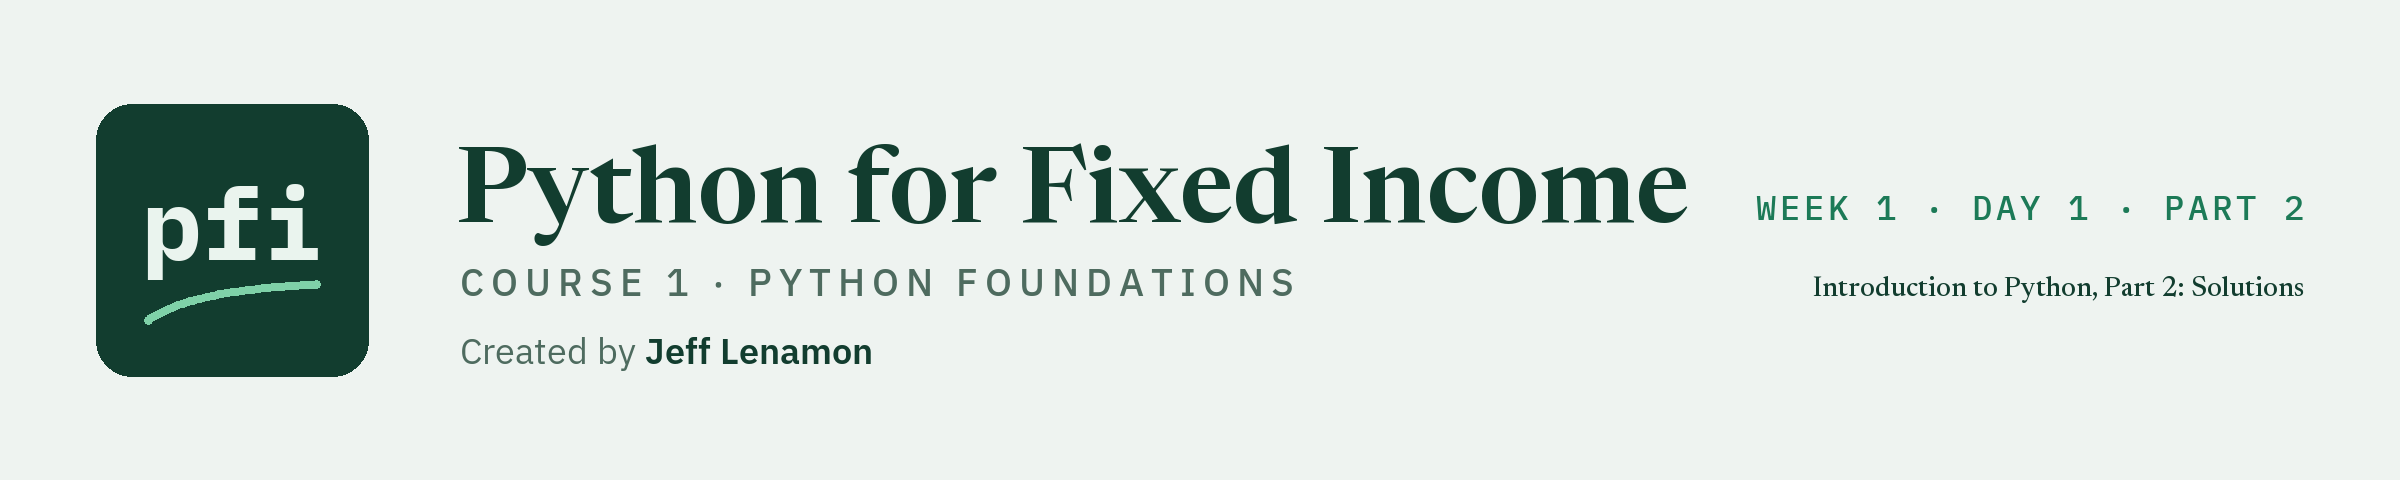

# Python for Fixed Income: Introduction, Part 2 - Solutions

Week 1, Day 1, Part 2. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week1/day1_part2/01_part2_python_for_fixed_income_intro_solutions.ipynb)

## Before You Start: Nothing to Install

This notebook uses only Python itself, so there is nothing to install.

## Exercises

The second desk from Part 1 is back, with the same three bonds.

Use what you learned above to answer its questions.

The issuers are invented.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Issuer</th><th align="left">Coupon (%)</th><th align="left">Maturity</th><th align="left">Price</th><th align="left">Rating</th><th align="left">Face held</th></tr>
<tr><td align="left">TRNW</td><td align="left">Tarnwick Utilities</td><td align="left">4.375</td><td align="left">2030</td><td align="left">96.25</td><td align="left">A</td><td align="left">2,000,000</td></tr>
<tr><td align="left">OSMC</td><td align="left">Osmere Chemicals</td><td align="left">5.00</td><td align="left">2035</td><td align="left">100.00</td><td align="left">BBB-</td><td align="left">1,250,000</td></tr>
<tr><td align="left">CLDB</td><td align="left">Calderby Retail</td><td align="left">8.25</td><td align="left">2031</td><td align="left">104.50</td><td align="left">B</td><td align="left">500,000</td></tr>
</table>
<br clear="left">

Replace each `...` with your own code, then run the check cell under it.

Run the next cell first.

It defines `check`, a small function that marks your answers, and it stores the desk's coupons, prices, and face amounts.

In [1]:
def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
    elif answer == expected:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)


# the second desk's three bonds, in the order of the table
coupon_list = [4.375, 5.0, 8.25]
price_list = [96.25, 100.0, 104.5]
face_list = [2000000, 1250000, 500000]

### Exercise 1

Q. Create a list that labels each of the three bonds as 'Premium', 'Discount', or 'Par' based on its price. Store it in **ex1_labels**. Use a loop with if, elif, and else.

In [2]:
# start with an empty list
ex1_labels = []
for price in price_list:
    if price > 100:
        ex1_labels.append('Premium')
    elif price < 100:
        ex1_labels.append('Discount')
    else:
        ex1_labels.append('Par')

print(ex1_labels)

['Discount', 'Par', 'Premium']


OSMC is priced at exactly 100, so it falls through both tests and lands in the `else`.

In [3]:
check('Exercise 1', ex1_labels, ['Discount', 'Par', 'Premium'])

Exercise 1: correct


### Exercise 2

Q. Write a function **position_cost** that takes a face amount and a price and returns the cost of the position. Then use it in a loop to find the total cost of the three positions, and store it in **ex2_total_cost**.

In [4]:
# define the function
def position_cost(face, price):
    """
    Take the face held and the price (per 100 face)
    and return the cost of the position.
    """
    return face * price / 100


# start a running total at zero
ex2_total_cost = 0
for face, price in zip(face_list, price_list):
    # add the cost of this position to the running total
    ex2_total_cost = ex2_total_cost + position_cost(face, price)

print(f'The three positions cost ${ex2_total_cost:,.2f}')

The three positions cost $3,697,500.00


In [5]:
check('Exercise 2 function', position_cost(2000000, 96.25), 1925000.0)
check('Exercise 2 total cost', ex2_total_cost, 3697500.0)

Exercise 2 function: correct
Exercise 2 total cost: correct


### Exercise 3

Q. Use a list comprehension to build a list of the annual coupon income of each position, in dollars, and store it in **ex3_incomes**.

In [6]:
# one calculation, for each pair of face and coupon
ex3_incomes = [face * coupon / 100 for face, coupon in zip(face_list, coupon_list)]

print(ex3_incomes)

[87500.0, 62500.0, 41250.0]


In [7]:
check('Exercise 3', ex3_incomes, [87500.0, 62500.0, 41250.0])

Exercise 3: correct


### Exercise 4

Q. Complete the function **coupon_income**. It takes a face amount, a coupon in percent, and a number of months that defaults to 12, and it returns the coupon income for that period in dollars.

In [8]:
def coupon_income(face, coupon, months=12):
    """
    Take the face held, the coupon (in percent), and the number of months,
    and return the coupon income for that period in dollars.
    """
    # the coupon is in percent, so divide by 100 for a year of income
    annual_income = face * coupon / 100
    # scale the year to the period asked for
    return annual_income * months / 12


print(f'TRNW pays ${coupon_income(2000000, 4.375):,.2f} in a year')
print(f'TRNW pays ${coupon_income(2000000, 4.375, months=6):,.2f} in six months')

TRNW pays $87,500.00 in a year
TRNW pays $43,750.00 in six months


The function returns a number and prints nothing itself, so the result can be formatted, stored, or used in another calculation.

In [9]:
check('Exercise 4 full year', coupon_income(2000000, 4.375), 87500.0)
check('Exercise 4 six months', coupon_income(2000000, 4.375, months=6), 43750.0)

Exercise 4 full year: correct
Exercise 4 six months: correct


### Exercise 5: AI check

You ask an AI assistant for code that totals the face held across the three positions.

It gives you the code below.

It was written for this course in the style of an AI answer, and it has one bug.

This is the routine from Part 1: read, predict, run, check.

Q. Read the code before you run it. What will it print? Then run it.

In [10]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
face_list = [2000000, 1250000, 500000]

for face in face_list:
    total_face = 0
    total_face = total_face + face

print(f'The total face held is {total_face:,}')

The total face held is 500,000


Q. Is that answer believable? Add up the three face amounts in the table yourself, and use that as your reference. Find the bug, and store the corrected total in **ex5_total_face**.

The code runs with no error and prints 500,000, which is only the last position.

The three face amounts add up to 3,750,000, so something is wrong.

The bug is the line `total_face = 0` inside the loop.

It resets the running total on every pass, so only the last face amount survives.

The total has to start at zero once, before the loop.

In [11]:
# start the running total once, before the loop
ex5_total_face = 0
for face in face_list:
    ex5_total_face = ex5_total_face + face

print(f'The total face held is {ex5_total_face:,}')

The total face held is 3,750,000


Code can run cleanly and still be wrong.

The habit is the same every time: read it, predict the answer, run it, and check it against a number you trust.

In [12]:
check('Exercise 5', ex5_total_face, 3750000)

Exercise 5: correct
